# Challenge 2: Make the Quantum Coin Biased

**IBM Quantum | Vishnu Institute of Technology | Qiskit Fall Fest 2026**

For this challenge, students must have a working Python environment with the following packages installed:
- `qiskit` v2.1.0 or newer
- `qiskit-ibm-runtime` v0.40.1 or newer
- `qiskit.visualization`
- `numpy`
- `pylatexenc`

To set up and install the packages above, see the [Install Qiskit](https://quantum.cloud.ibm.com/docs/guides/install-qiskit) guide. In order to run jobs on real quantum computers, you need an IBM Quantum&reg; account (see [Set up your IBM Cloud&reg; account](https://quantum.cloud.ibm.com/docs/guides/cloud-setup)) with an **API key** and an **instance (CRN)**.

In [2]:
# Uncomment and modify this line as needed to install dependencies
#%pip install --upgrade "qiskit[visualization]" qiskit-ibm-runtime numpy pylatexenc

In [3]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram

## Introduction

A Hadamard gate creates an equal superposition of $\vert 0\rangle$ and $\vert 1\rangle$, like a fair coin. In this challenge we **bias** the coin: we use gates so that the probabilities of measuring 0 and 1 are different.

### The key idea

A qubit state is $\vert\psi\rangle = c_0\vert 0\rangle + c_1\vert 1\rangle$, and measurement gives 0 with probability $\vert c_0\vert^2$ and 1 with probability $\vert c_1\vert^2$.

**$R_y(\theta)$ gate:** rotates the qubit by an angle $\theta$:

$$R_y(\theta)\vert 0\rangle = \cos(\theta/2)\vert 0\rangle + \sin(\theta/2)\vert 1\rangle$$

so $P(0)=\cos^2(\theta/2)$ and $P(1)=\sin^2(\theta/2)$. Choosing $\theta$ chooses the bias.

**$T$ gate:** adds a phase $\pi/4$ to $\vert 1\rangle$. On its own it does not change probabilities, but between two Hadamards ($H$, $T$, $H$) it converts a phase difference into unequal probabilities.

## Qiskit patterns framework

We follow the Qiskit patterns workflow, a general procedure for solving problems with a quantum computer:

1. **Mapping** the problem to quantum circuits
2. **Optimizing** the circuits for the target hardware
3. **Executing** on the hardware
4. **Post-processing** the results

All circuits below use `measure_all()`, so the results are stored in the classical register called `meas`. Remember that Qiskit uses **little-endian** notation: in a bitstring such as `01`, the rightmost bit is qubit 0.

#### 1. Mapping

**Main circuit:** $R_y(\pi/3)$ then measure (1 gate before measurement, 1 qubit).

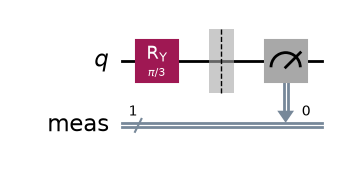

In [4]:
theta = np.pi / 3

qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc.measure_all()
qc.draw("mpl")

### Think before you run: predictions

- **Which occurs more often?** $P(0)=\cos^2(\pi/6)=0.75$ and $P(1)=\sin^2(\pi/6)=0.25$, so **0 occurs more often**.
- **Approximate percentages:** about **75% zeros and 25% ones**.
- **If we change the gates?** A different angle $\theta$ changes the bias: small $\theta$ favours 0, large $\theta$ (towards $\pi$) favours 1, and $\theta=\pi/2$ gives a fair coin.

We will also build circuits for different degrees of bias, the **bonus** pair, and a gate-only version ($H$, $T$, $H$).

In [5]:
# Different degrees of bias
angles = {
    "theta=pi/6 (P0~93%)": np.pi / 6,
    "theta=pi/3 (P0=75%)": np.pi / 3,
    "theta=pi/2 (P0=50%)": np.pi / 2,
    "theta=2pi/3 (P0=25%)": 2 * np.pi / 3,
    "theta=5pi/6 (P0~7%)": 5 * np.pi / 6,
}
sweep = []
for t in angles.values():
    q = QuantumCircuit(1)
    q.ry(t, 0)
    q.measure_all()
    sweep.append(q)

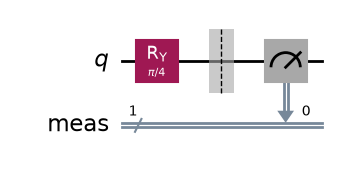

In [6]:
# Bonus circuit 1: 0 occurs more frequently  -> P(0) = cos^2(pi/8) ~ 85%
qc_zero = QuantumCircuit(1)
qc_zero.ry(np.pi / 4, 0)
qc_zero.measure_all()

# Bonus circuit 2: 1 occurs more frequently  -> P(1) = sin^2(3pi/8) ~ 85%
qc_one = QuantumCircuit(1)
qc_one.ry(3 * np.pi / 4, 0)
qc_one.measure_all()

qc_zero.draw("mpl")

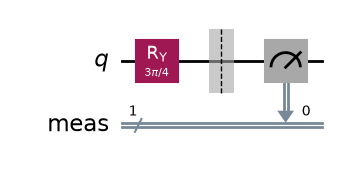

In [7]:
qc_one.draw("mpl")

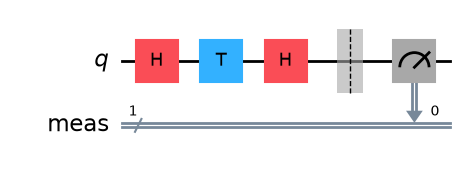

In [8]:
# Gate-only alternative: H, T, H  -> P(0) = cos^2(pi/8) ~ 85%
qc_hth = QuantumCircuit(1)
qc_hth.h(0)
qc_hth.t(0)
qc_hth.h(0)
qc_hth.measure_all()
qc_hth.draw("mpl")

#### 2. Optimizing

Next, we optimize the circuits for the quantum hardware using the transpiler. It assigns the logical qubits to physical qubits on the processor and rewrites the gates in terms of the hardware's native gate set. We choose an optimization level from 0 (none) to 3 (highest); see [Set transpiler optimization level](https://quantum.cloud.ibm.com/docs/guides/set-optimization). The transpiled circuit looks different from the logical one we mapped.

In [10]:
# Load the Qiskit Runtime service
from qiskit_ibm_runtime import QiskitRuntimeService

# Syntax for first saving your credentials. Delete these lines after saving them once,
# and never share a notebook that contains your real API key.
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    instance="<YOUR_INSTANCE_CRN>",
    token="<YOUR_API_KEY>",
    overwrite=True,
    set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_quantum_platform")

# Load saved credentials (use this line on later runs)
# service = QiskitRuntimeService()

# Use the least busy backend, or uncomment the loading of a specific backend.
backend = service.least_busy(operational=True, simulator=False)
# backend = service.backend("ibm_brisbane")
print(backend.name)

ibm_marrakesh


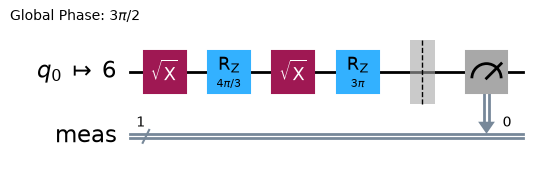

In [11]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)

# order: main, 5 sweep circuits, bonus (0), bonus (1), H-T-H
circuits = [qc] + sweep + [qc_zero, qc_one, qc_hth]
isa_circuits = pm.run(circuits)

isa_circuits[0].draw("mpl", idle_wires=False)

#### 3. Executing

A "Sampler" is a primitive that samples the possible states resulting from a quantum circuit and collects statistics on what is measured and with what probability. We send **all circuits as a single job** with **100 shots** each.

In [12]:
# Load the Runtime primitive
from qiskit_ibm_runtime.executor_sampler import Sampler

sampler = Sampler(mode=backend)

In [13]:
job = sampler.run(isa_circuits, shots=100)
print("Job ID:", job.job_id())

res = job.result()   # waits until the job finishes
all_counts = [r.data.meas.get_counts() for r in res]
counts_main = all_counts[0]
sweep_counts = all_counts[1:6]
counts_zero, counts_one, counts_hth = all_counts[6:9]
print("Main circuit:", counts_main)

Job ID: db5qnpamb58s738asne0
Main circuit: {'1': 27, '0': 73}


#### 4. Post-processing

Now we view the results as histograms of the 100 shots of each circuit.

Predicted P(0) = 0.75, P(1) = 0.25
Measured counts: {'1': 27, '0': 73}


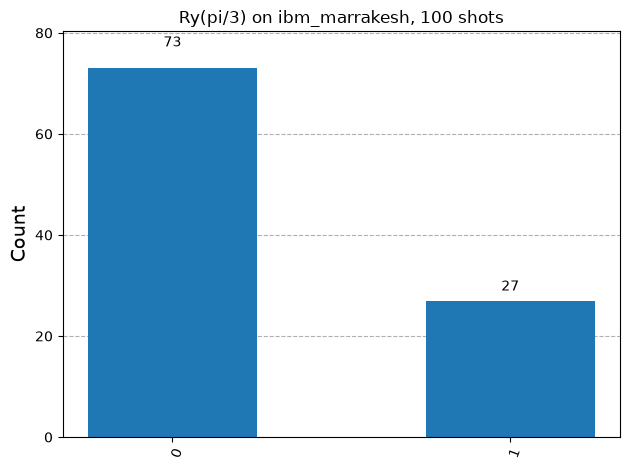

In [14]:
print(f"Predicted P(0) = {np.cos(theta/2)**2:.2f}, P(1) = {np.sin(theta/2)**2:.2f}")
print("Measured counts:", counts_main)
plot_histogram(counts_main, title=f"Ry(pi/3) on {backend.name}, 100 shots")

#### Different degrees of bias

theta=pi/6 (P0~93%)    predicted P(0) = 0.93   measured = {'0': 92, '1': 8}
theta=pi/3 (P0=75%)    predicted P(0) = 0.75   measured = {'0': 68, '1': 32}
theta=pi/2 (P0=50%)    predicted P(0) = 0.50   measured = {'1': 30, '0': 70}
theta=2pi/3 (P0=25%)   predicted P(0) = 0.25   measured = {'1': 75, '0': 25}
theta=5pi/6 (P0~7%)    predicted P(0) = 0.07   measured = {'0': 6, '1': 94}


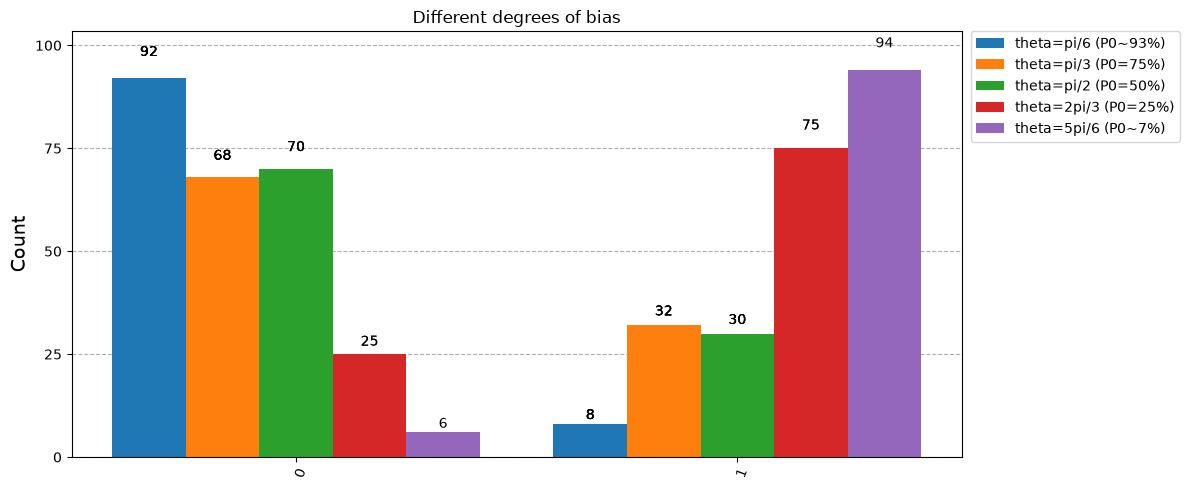

In [15]:
for (label, t), c in zip(angles.items(), sweep_counts):
    print(f"{label:22s} predicted P(0) = {np.cos(t/2)**2:.2f}   measured = {c}")
plot_histogram(sweep_counts, legend=list(angles.keys()),
               title="Different degrees of bias", figsize=(12, 5))

#### Bonus: one circuit biased towards 0, one towards 1

Biased to 0: {'0': 88, '1': 12}
Biased to 1: {'1': 83, '0': 17}


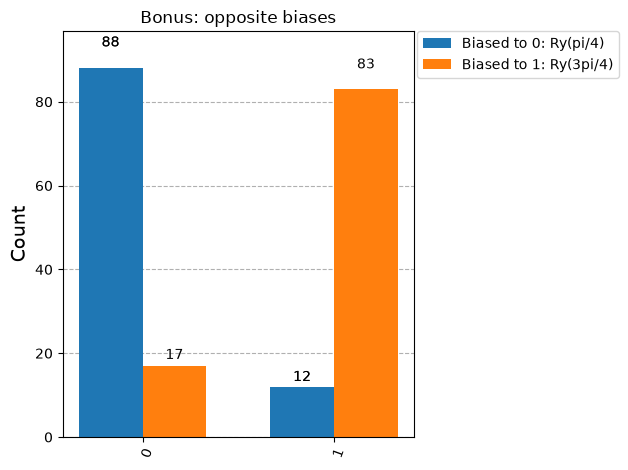

In [16]:
print("Biased to 0:", counts_zero)
print("Biased to 1:", counts_one)
plot_histogram([counts_zero, counts_one],
               legend=["Biased to 0: Ry(pi/4)", "Biased to 1: Ry(3pi/4)"],
               title="Bonus: opposite biases")

#### Gate-only version: $H$, $T$, $H$

H-T-H: {'0': 85, '1': 15}


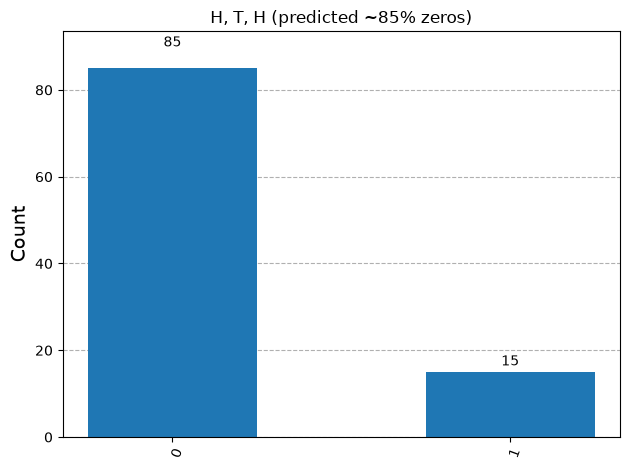

In [17]:
print("H-T-H:", counts_hth)
plot_histogram(counts_hth, title="H, T, H (predicted ~85% zeros)")

### How the gates changed the distribution

A Hadamard alone gives equal amplitudes, hence a 50/50 coin. The $R_y(\theta)$ gate instead tilts the state away from $\vert 0\rangle$ so that the amplitudes become $\cos(\theta/2)$ and $\sin(\theta/2)$. Since probabilities are the squares of the amplitudes, a small $\theta$ favours 0 and a large $\theta$ favours 1. In the $H$, $T$, $H$ circuit, the $T$ gate adds a phase between the two components and the second Hadamard turns that phase difference into unequal amplitudes.

The measured percentages are close to the predicted ones. Small differences come from the finite number of shots (100) and from hardware noise.